# AV + earthquake: demo analysis (Phase 6)

1-iteration Sioux Falls runs (1% sample, 3,608 agents): **baseline** vs **damage**
(artery degraded + link closed at 08:30) vs **quake** (damage + D5 destination
redirect). All metrics come from `analyze.py`; this notebook only displays.
Sweep cells (`output/sweep/...`) plug into the same functions.

In [1]:
import sys
from pathlib import Path
CWD = Path.cwd()
ROOT = CWD.parent if CWD.name == 'scripts' else CWD
sys.path.insert(0, str(ROOT / 'scripts'))
FIG = ROOT / 'output' / 'demo' / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import analyze

T_QUAKE = 8.5 * 3600
RUNS = {
    'baseline': str(ROOT / 'output' / 'demo' / 'baseline'),
    'damage': str(ROOT / 'output' / 'demo' / 'damage'),
    'quake': str(ROOT / 'output' / 'demo' / 'quake'),
}
trips = {label: analyze.read_trips(d) for label, d in RUNS.items()}
print({label: len(df) for label, df in trips.items()})

{'baseline': 7216, 'damage': 7216, 'quake': 4587}


## 1. Run comparison table (Phase 6 validation checklist inputs)

In [2]:
summary = analyze.compare_runs(RUNS, T_QUAKE)
summary.T

,0,1,2
run,baseline,damage,quake
trip_n_trips,7216,7216,4587
trip_mean_min,156.23428,198.8237,124.807579
trip_median_min,87.333333,98.233333,46.1
trip_n_postquake,4244,4244,1616
trip_post_mean_min,142.091227,177.820272,39.738892
trip_post_median_min,54.4,65.525,14.216667
mode_car,7216,7216,4587
stuck_events,0,0,0
redirect_home,NaN,NaN,2137.0


## 2. Redirect outcomes (D5 splits: home / hospital / stay / random)

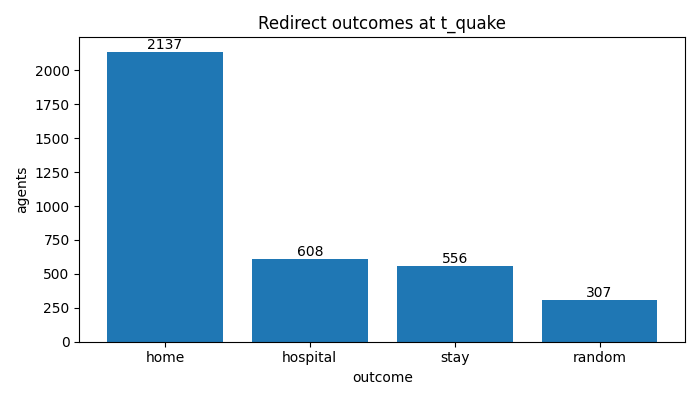

{'home': 2137, 'hospital': 608, 'stay': 556, 'random': 307}


In [3]:
redirect_log = analyze.read_redirect_log(RUNS['quake'])
fig, ax = plt.subplots(figsize=(7, 4))
analyze.plot_redirect_outcomes(ax, redirect_log)
fig.tight_layout()
fig.savefig(str(FIG / 'redirect-outcomes.png'))
from IPython.display import Image, display
display(Image(str(FIG / 'redirect-outcomes.png')))
print(redirect_log['outcome'].value_counts().to_dict())

## 3. Travel-time distributions (overall)

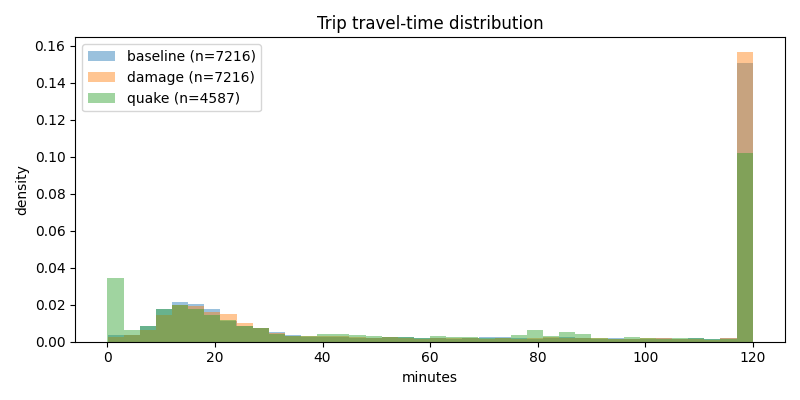

baseline {'n_trips': 7216, 'mean_min': 156.2342803030303, 'median_min': 87.33333333333333, 'n_postquake': 4244, 'post_mean_min': 142.09122683003454, 'post_median_min': 54.4}
damage {'n_trips': 7216, 'mean_min': 198.82369964892834, 'median_min': 98.23333333333333, 'n_postquake': 4244, 'post_mean_min': 177.82027175620485, 'post_median_min': 65.525}
quake {'n_trips': 4587, 'mean_min': 124.80757939103263, 'median_min': 46.1, 'n_postquake': 1616, 'post_mean_min': 39.738892326732675, 'post_median_min': 14.216666666666667}


In [4]:
fig, ax = plt.subplots(figsize=(8, 4))
analyze.plot_travel_time_hist(ax, trips)
fig.tight_layout()
fig.savefig(str(FIG / 'travel-times.png'))
from IPython.display import Image, display
display(Image(str(FIG / 'travel-times.png')))
for label, df in trips.items():
    print(label, analyze.trip_travel_stats(df))

## 4. Hospital access (the emergency metric)

{'n_hospital_agents': 608, 'n_postquake_legs': 267, 'mean_min': 74.20674157303371, 'median_min': 25.833333333333332, 'p90_min': 202.20000000000002}


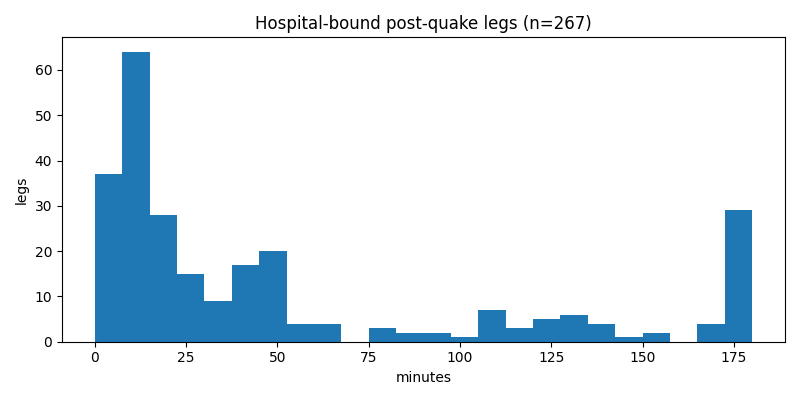

In [5]:
print(analyze.hospital_trip_stats(trips['quake'], redirect_log, T_QUAKE))
fig, ax = plt.subplots(figsize=(8, 4))
analyze.plot_hospital_arrivals(ax, trips['quake'], redirect_log, T_QUAKE)
fig.tight_layout()
fig.savefig(str(FIG / 'hospital-access.png'))
from IPython.display import Image, display
display(Image(str(FIG / 'hospital-access.png')))


## 5. Link-volume shifts (rerouting evidence)

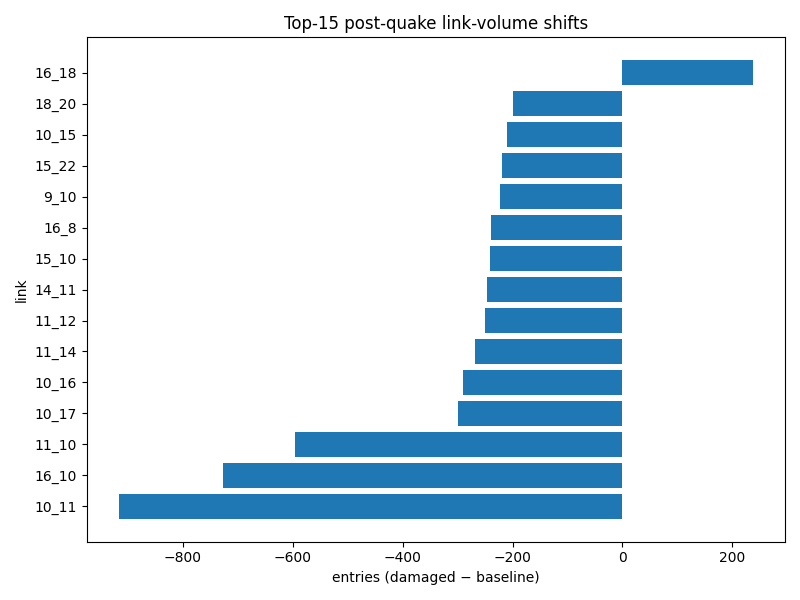

 link  before_base  after_base  before_quake  after_quake  delta
10_11          320        1102           320          185   -917
16_10          295         940           295          214   -726
11_10          225         881           225          285   -596
10_17           94         373            93           74   -299
10_16          188         641           188          350   -291
11_14          133         448           133          180   -268
11_12           95         428            95          178   -250
14_11          180         360           180          114   -246


In [6]:
base_vols = analyze.link_entries(RUNS['baseline'], T_QUAKE)
quake_vols = analyze.link_entries(RUNS['quake'], T_QUAKE)
fig, ax = plt.subplots(figsize=(8, 6))
analyze.plot_link_shift(ax, base_vols, quake_vols)
fig.tight_layout()
fig.savefig(str(FIG / 'link-shift.png'))
from IPython.display import Image, display
display(Image(str(FIG / 'link-shift.png')))
merged = base_vols.merge(quake_vols, on='link', suffixes=('_base', '_quake'))
merged['delta'] = merged['after_quake'] - merged['after_base']
print(merged.sort_values('delta').head(8).to_string(index=False))

## 6. Completion + stuck (mass conservation)

In [7]:
for label, d in RUNS.items():
    print(label, 'trips:', len(trips[label]), 'stuck:', analyze.count_stuck(d))

baseline trips: 7216 stuck: 0


damage trips: 7216 stuck: 0
quake trips: 4587 stuck: 0
